# Proyecto final · INC-2505 Análisis y exploración de datos
## ¿A quién y cómo promocionar? Segmentación de clientes de la cafetería universitaria *Café La Corona*

**Autor:** Denis Corona · matrícula: _(escríbela aquí)_ &nbsp;·&nbsp; **Fecha:** noviembre 2026

---
## U1 · Situación, pregunta de decisión y datos

**Situación.** *Café La Corona* es una cafetería dentro de un campus universitario. Tiene una app de lealtad donde se registra cada cliente con un ID anónimo. El administrador tiene presupuesto para promociones el próximo semestre, pero hoy da el mismo descuento a todos y no sabe si le conviene.

**Pregunta de decisión.**
> ¿Qué tipos de clientes tiene *Café La Corona* y qué acción distinta conviene aplicar a cada uno para aumentar visitas y gasto con el presupuesto de promociones?

**Descripción del dataset** (320 clientes, un renglón por cliente):

| Variable | Tipo | Descripción |
|---|---|---|
| `id_cliente` | Identificador (texto) | ID anónimo, sin nombre ni datos de contacto |
| `tipo_cliente` | Categórica nominal | Estudiante / Docente / Administrativo |
| `tarjeta_lealtad` | Categórica binaria | Sí / No |
| `turno_preferido` | Categórica binaria | Mañana / Tarde |
| `visitas_mes` | Numérica discreta | Visitas promedio al mes |
| `gasto_promedio` | Numérica continua | Gasto promedio por visita (MXN) |
| `tiempo_espera_min` | Numérica continua | Minutos promedio de espera en fila |
| `antiguedad_meses` | Numérica discreta | Meses desde que se registró en la app |
| `satisfaccion` | Ordinal (1–10) | Calificación promedio que da el cliente |

**Fuente.** Dataset **propio y simulado**, generado con el script `generar_datos.py` (semilla fija, reproducible). Se diseñó imitando lo que registraría la app de una cafetería, incluyendo **problemas de calidad intencionales** (valores faltantes por fallas de registro y outliers por pedidos de catering y fallas en caja). No proviene de internet ni de ejemplos vistos en clase.

**Consideración ética y protocolo de manejo de datos.**
- *Riesgo identificado:* si fuera información real, cruzar `tipo_cliente`, turno y hábitos podría **re-identificar** a una persona (p. ej. un docente de la tarde con compras muy altas).
- *Protocolo:* (1) solo ID anónimo, sin nombre, correo ni matrícula; (2) consentimiento informado al registrarse en la app; (3) acceso solo para el administrador; (4) resultados siempre **agregados por segmento**, nunca por persona; (5) los segmentos se usan para ofrecer beneficios, **no** para excluir ni cobrar distinto a nadie; (6) conservar los datos solo el semestre necesario.
- *Por qué el dataset sirve para la pregunta:* contiene frecuencia, gasto y antigüedad (las tres dimensiones clásicas para segmentar clientes), un grupo de comparación natural (con/sin tarjeta) y una variable operativa que el administrador puede mover (tiempo de espera).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df_raw = pd.read_csv("data/clientes_cafeteria_raw.csv")
print(df_raw.shape)
df_raw.head()

(320, 9)


,id_cliente,tipo_cliente,tarjeta_lealtad,turno_preferido,visitas_mes,gasto_promedio,tiempo_espera_min,antiguedad_meses,satisfaccion
0,C0001,Estudiante,Sí,Tarde,12,38.70,14.0,13,8.0
1,C0002,Administrativo,Sí,Tarde,15,41.41,9.3,9,9.0
2,C0003,Estudiante,Sí,Mañana,21,84.24,4.0,31,9.0
3,C0004,Estudiante,Sí,Tarde,6,39.02,9.0,3,7.0
4,C0005,Administrativo,Sí,Mañana,15,43.53,11.4,12,7.0


In [2]:
df_raw.dtypes

id_cliente               str
tipo_cliente             str
tarjeta_lealtad          str
turno_preferido          str
visitas_mes            int64
gasto_promedio       float64
tiempo_espera_min    float64
antiguedad_meses       int64
satisfaccion         float64
dtype: object

---
## U2 · Estadística descriptiva y exploratoria
Primero se exploran los datos **tal como llegaron** (sin limpiar) para detectar problemas.

In [3]:
num = ["visitas_mes", "gasto_promedio", "tiempo_espera_min", "antiguedad_meses", "satisfaccion"]

def resumen(d, cols):
    r = pd.DataFrame({
        "media": d[cols].mean(),
        "mediana": d[cols].median(),
        "desv_est": d[cols].std(),
        "min": d[cols].min(),
        "max": d[cols].max(),
    })
    r["rango"] = r["max"] - r["min"]
    return r.round(2)

resumen(df_raw, num)

,media,mediana,desv_est,min,max,rango
visitas_mes,12.23,13.00,6.07,1.00,26.00,25.0
gasto_promedio,70.68,59.46,39.82,25.04,328.04,303.0
tiempo_espera_min,8.54,8.00,5.21,1.00,52.00,51.0
antiguedad_meses,12.26,13.00,8.40,1.00,35.00,34.0
satisfaccion,8.33,8.00,1.04,5.00,10.00,5.0


**Interpretación.** En `gasto_promedio` la **media (≈ 70.7) es mucho mayor que la mediana (≈ 59.5)** y el máximo es ≈ 328 MXN: señal de asimetría a la derecha causada por pocos valores extremos. En `tiempo_espera_min` pasa algo parecido (máximo de 52 min con una espera típica de ~8). Cuando media y mediana se separan así, la **mediana describe mejor al cliente típico**; esto justificará las decisiones de la U3.

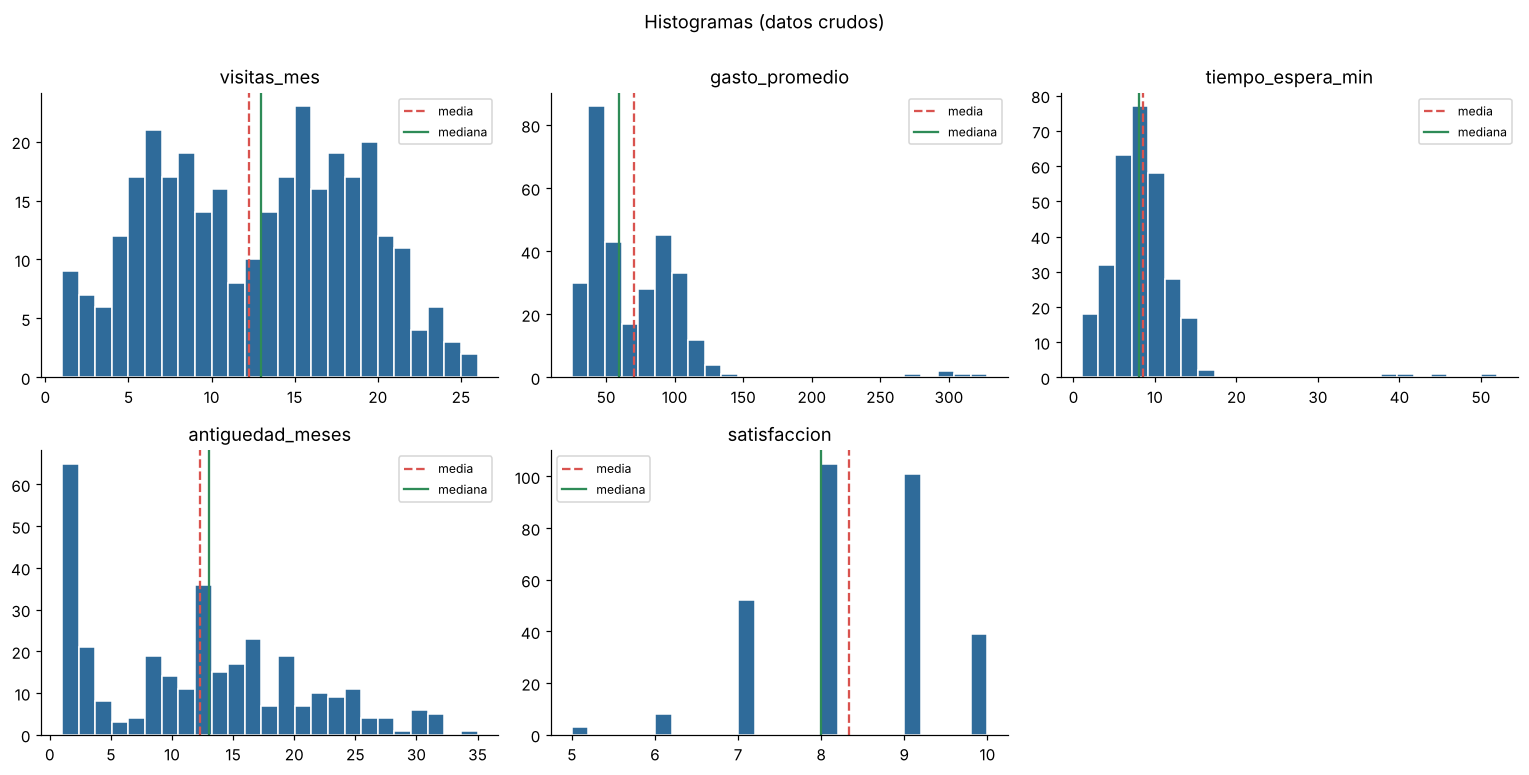

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axs.ravel(), num):
    ax.hist(df_raw[c].dropna(), bins=25, color="#2F6B9A", edgecolor="white")
    ax.axvline(df_raw[c].mean(), color="#D9534F", ls="--", label="media")
    ax.axvline(df_raw[c].median(), color="#2E8B57", ls="-", label="mediana")
    ax.set_title(c); ax.legend(fontsize=8)
axs.ravel()[-1].axis("off")
plt.suptitle("Histogramas (datos crudos)", y=1.0); plt.tight_layout(); plt.show()

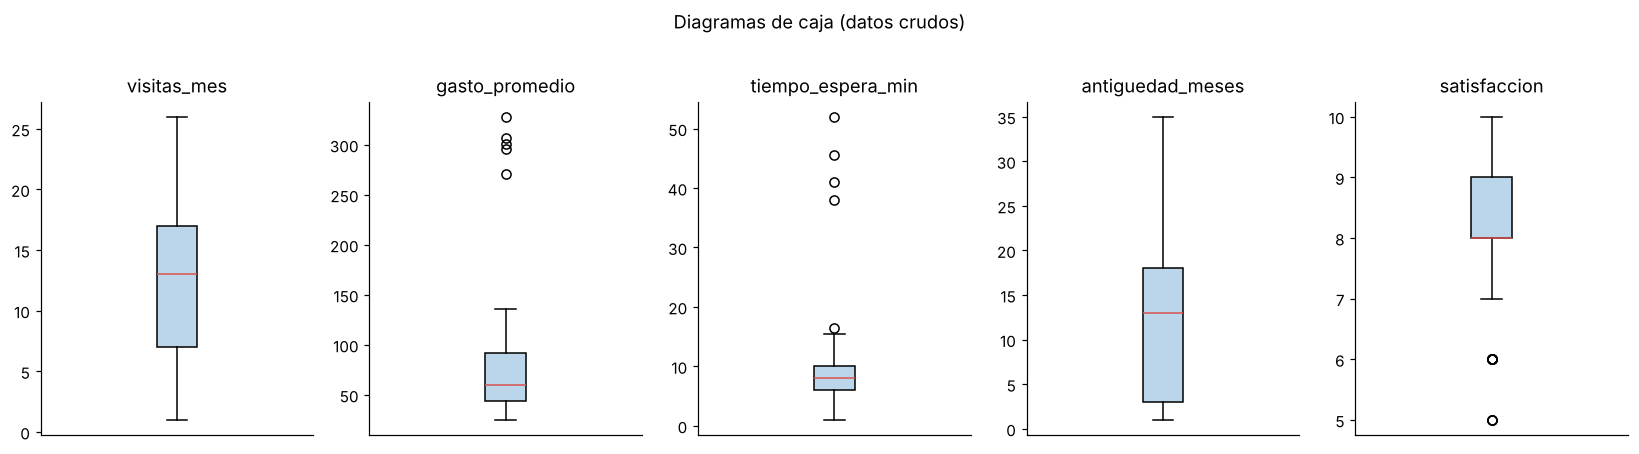

In [5]:
fig, axs = plt.subplots(1, 5, figsize=(15, 4))
for ax, c in zip(axs, num):
    ax.boxplot(df_raw[c].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor="#BBD6EA"), medianprops=dict(color="#D9534F"))
    ax.set_title(c); ax.set_xticks([])
plt.suptitle("Diagramas de caja (datos crudos)", y=1.02); plt.tight_layout(); plt.show()

### Regla de Tukey (1.5 × IQR)
Un valor es atípico si está por debajo de `Q1 − 1.5·IQR` o por encima de `Q3 + 1.5·IQR`.

In [6]:
def limites_tukey(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

filas = []
for c in num:
    lo, hi = limites_tukey(df_raw[c])
    n_out = ((df_raw[c] < lo) | (df_raw[c] > hi)).sum()
    filas.append({"variable": c, "límite_inf": round(lo, 2), "límite_sup": round(hi, 2), "n_atípicos": n_out})
pd.DataFrame(filas)

,variable,límite_inf,límite_sup,n_atípicos
0,visitas_mes,-8.00,32.00,0
1,gasto_promedio,-28.53,164.06,5
2,tiempo_espera_min,-0.27,16.32,5
3,antiguedad_meses,-19.50,40.50,0
4,satisfaccion,6.50,10.50,11


In [7]:
lo, hi = limites_tukey(df_raw["gasto_promedio"])
print("Atípicos de gasto_promedio por encima de", round(hi, 1), "MXN:")
df_raw[df_raw["gasto_promedio"] > hi][["id_cliente", "tipo_cliente", "turno_preferido", "gasto_promedio"]]

Atípicos de gasto_promedio por encima de 164.1 MXN:


,id_cliente,tipo_cliente,turno_preferido,gasto_promedio
13,C0014,Administrativo,Tarde,306.34
72,C0073,Administrativo,Mañana,270.36
77,C0078,Administrativo,Mañana,300.93
103,C0104,Administrativo,Mañana,296.25
299,C0300,Administrativo,Mañana,328.04


In [8]:
lo, hi = limites_tukey(df_raw["tiempo_espera_min"])
print("Atípicos de tiempo_espera_min por encima de", round(hi, 1), "min:")
df_raw[df_raw["tiempo_espera_min"] > hi][["id_cliente", "turno_preferido", "tiempo_espera_min", "visitas_mes"]]

Atípicos de tiempo_espera_min por encima de 16.3 min:


,id_cliente,turno_preferido,tiempo_espera_min,visitas_mes
33,C0034,Mañana,52.0,11
69,C0070,Mañana,38.0,15
87,C0088,Mañana,16.4,9
163,C0164,Mañana,41.0,20
269,C0270,Tarde,45.5,21


**Anomalías propias del problema (explicadas).**
- **Gasto > ~165 MXN:** son **5 clientes, todos del tipo Administrativo, con gasto de 270–328 MXN por visita**. Una persona no gasta eso en un café; corresponden a **pedidos de catering** (juntas, eventos de oficina) registrados como consumo individual. No son errores de captura, pero **distorsionan la media** y no representan al cliente típico.
- **Espera > ~16 min:** 5 casos. Cuatro son extremos (**38 a 52 minutos**), compatibles con **fallas en caja o en la app** (terminal caída), no con una fila normal; el quinto (16.4 min) apenas rebasa el límite y es una espera larga pero plausible.

Por tipo de cliente:


visitas_mes        gasto_promedio        antiguedad_meses  \
                      mean median           mean median             mean   
tipo_cliente                                                               
Administrativo        11.6   11.0           95.2   77.7             11.9   
Docente               12.4   12.0           63.2   52.1             10.9   
Estudiante            12.3   13.0           67.2   58.2             12.7   

                       
               median  
tipo_cliente           
Administrativo   12.0  
Docente          12.0  
Estudiante       13.0

Por tarjeta de lealtad:


visitas_mes        gasto_promedio        antiguedad_meses  \
                       mean median           mean median             mean   
tarjeta_lealtad                                                             
No                     10.4    9.0           67.9   52.0              8.9   
Sí                     14.3   15.0           74.0   78.2             16.0   

                        
                median  
tarjeta_lealtad         
No                 8.5  
Sí                15.0

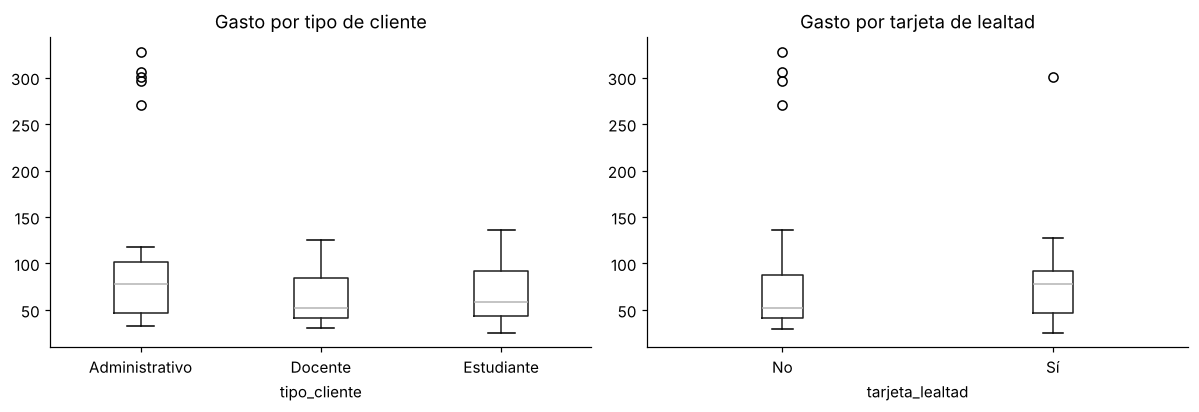

In [9]:
# Comparación entre subgrupos (datos crudos)
print("Por tipo de cliente:")
display(df_raw.groupby("tipo_cliente")[["visitas_mes", "gasto_promedio", "antiguedad_meses"]].agg(["mean", "median"]).round(1))
print("Por tarjeta de lealtad:")
display(df_raw.groupby("tarjeta_lealtad")[["visitas_mes", "gasto_promedio", "antiguedad_meses"]].agg(["mean", "median"]).round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
df_raw.boxplot(column="gasto_promedio", by="tipo_cliente", ax=axs[0], grid=False)
df_raw.boxplot(column="gasto_promedio", by="tarjeta_lealtad", ax=axs[1], grid=False)
axs[0].set_title("Gasto por tipo de cliente"); axs[1].set_title("Gasto por tarjeta de lealtad")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Conclusión accionable de la U2.** (1) Los clientes **con tarjeta gastan más por visita** que los que no la tienen, lo que se probará formalmente en la U4. (2) El personal administrativo concentra el gasto extremo (promedio de 95 MXN vs. 63–67 de los demás); como son pedidos de catering, conviene **registrarlos como una categoría aparte** en la app para no contaminar los análisis de consumo individual.

---
## U3 · Preparación y limpieza de datos
Se aplican **tres técnicas, en este orden**: imputación → capping → estandarización.

### 3.1 Valores faltantes

In [10]:
faltantes = df_raw.isna().sum().to_frame("n_faltantes")
faltantes["%"] = (faltantes["n_faltantes"] / len(df_raw) * 100).round(1)
faltantes[faltantes.n_faltantes > 0]

,n_faltantes,%
gasto_promedio,16,5.0
tiempo_espera_min,21,6.6
satisfaccion,12,3.8


### 3.2 Técnica 1 · Imputación por **mediana**
**Por qué la mediana y no la media:** `gasto_promedio` y `tiempo_espera_min` tienen valores extremos que inflan la media (la media de gasto ≈ 70.7 vs. mediana ≈ 59.5). Imputar con la media pondría un valor "inflado" por los pedidos de catering a todos los faltantes. La mediana es **robusta** a los atípicos.
**Por qué no eliminar renglones:** perderíamos hasta ~15 % de los clientes y la información de sus otras variables.

In [11]:
df = df_raw.copy()
medianas = {}
for c in ["gasto_promedio", "tiempo_espera_min", "satisfaccion"]:
    medianas[c] = df[c].median()
    df[c] = df[c].fillna(medianas[c])
print("Medianas usadas:", {k: round(v, 2) for k, v in medianas.items()})
print("Faltantes restantes:", int(df.isna().sum().sum()))

Medianas usadas: {'gasto_promedio': np.float64(59.46), 'tiempo_espera_min': np.float64(8.0), 'satisfaccion': np.float64(8.0)}
Faltantes restantes: 0


### 3.3 Técnica 2 · Capping (winsorización) con límites de Tukey
Los valores por encima del límite superior de Tukey se **reemplazan por el propio límite**.
**Por qué capping y no eliminarlos:** los clientes atípicos siguen siendo clientes reales; solo queremos que su valor extremo no domine el análisis. Eliminar renglones perdería también su frecuencia y antigüedad.

In [12]:
df_antes_cap = df.copy()
for c in ["gasto_promedio", "tiempo_espera_min"]:
    lo, hi = limites_tukey(df[c])
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    df[c] = df[c].clip(lower=max(lo, 0), upper=hi)
    print(f"{c}: {n} valores ajustados al rango [{max(lo,0):.1f}, {hi:.1f}]")

gasto_promedio: 5 valores ajustados al rango [0.0, 160.3]
tiempo_espera_min: 5 valores ajustados al rango [0.7, 15.6]


### 3.4 Técnica 3 · Estandarización **z-score**
`z = (x − media) / desviación estándar` deja cada variable con media 0 y desv. est. 1.
**Por qué z-score y no min-max:** K-means usa distancias euclidianas, y si `gasto` está en pesos (25–165) y `visitas` en unidades (1–26), el gasto dominaría. Min-max depende de los extremos (muy sensible a atípicos); z-score es el estándar para métodos basados en distancia.

In [13]:
vars_km = ["visitas_mes", "gasto_promedio", "antiguedad_meses"]
scaler = StandardScaler()
Z = scaler.fit_transform(df[vars_km])
df_z = pd.DataFrame(Z, columns=[f"z_{c}" for c in vars_km], index=df.index)
df_z.describe().loc[["mean", "std"]].round(3)

,z_visitas_mes,z_gasto_promedio,z_antiguedad_meses
mean,0.000,0.000,-0.000
std,1.002,1.002,1.002


### 3.5 Antes vs. después (el efecto de la limpieza)

,media_antes,media_después,desv_antes,desv_después,máx_antes,máx_después
gasto_promedio,70.68,67.93,39.82,28.25,328.04,160.35
tiempo_espera_min,8.54,8.14,5.21,3.10,52.00,15.59


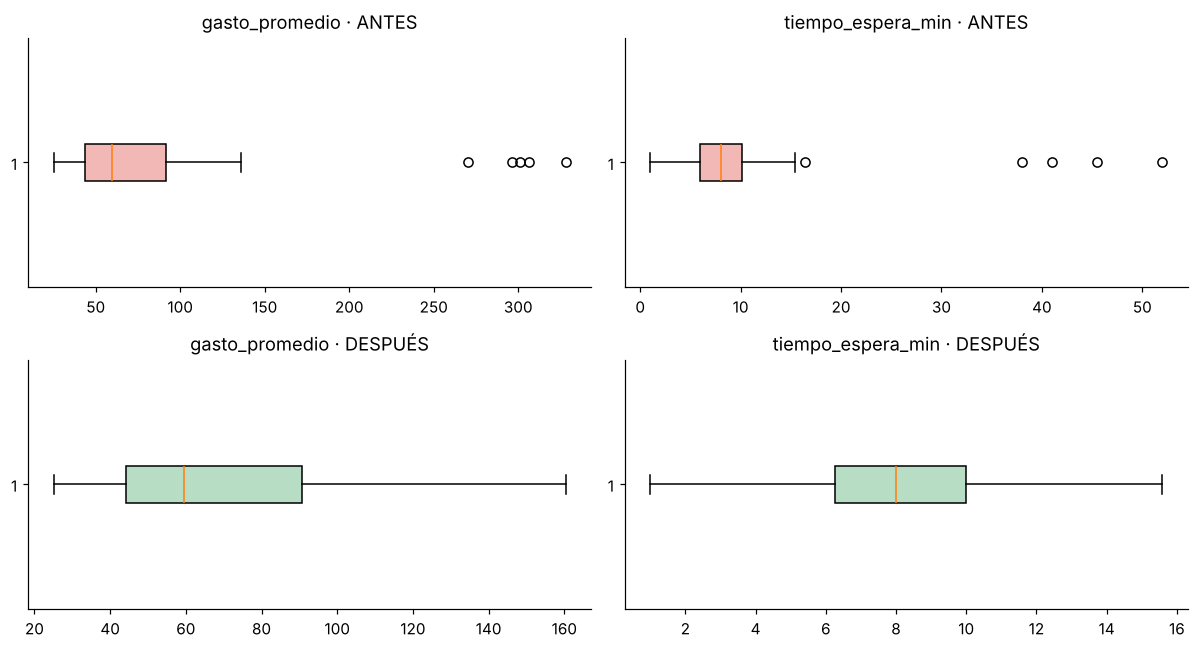

In [14]:
comp = pd.DataFrame({
    "media_antes":   df_raw[["gasto_promedio", "tiempo_espera_min"]].mean(),
    "media_después": df[["gasto_promedio", "tiempo_espera_min"]].mean(),
    "desv_antes":    df_raw[["gasto_promedio", "tiempo_espera_min"]].std(),
    "desv_después":  df[["gasto_promedio", "tiempo_espera_min"]].std(),
    "máx_antes":     df_raw[["gasto_promedio", "tiempo_espera_min"]].max(),
    "máx_después":   df[["gasto_promedio", "tiempo_espera_min"]].max(),
}).round(2)
display(comp)

fig, axs = plt.subplots(2, 2, figsize=(11, 6))
for j, c in enumerate(["gasto_promedio", "tiempo_espera_min"]):
    axs[0, j].boxplot(df_raw[c].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor="#F2B8B5"))
    axs[0, j].set_title(f"{c} · ANTES")
    axs[1, j].boxplot(df[c], vert=False, patch_artist=True, boxprops=dict(facecolor="#B7DDC4"))
    axs[1, j].set_title(f"{c} · DESPUÉS")
plt.tight_layout(); plt.show()

**Efecto de la limpieza.** La desviación estándar del gasto baja de ≈ 39.8 a ≈ 28.3 y la de la espera de ≈ 5.2 a ≈ 3.1; el máximo del gasto pasa de 328 a 160 MXN y el de la espera de 52 a 15.6 min. Sin esta limpieza, el K-means habría formado un grupo "de catering" con 5 personas en vez de segmentos útiles, y la regresión de la U4 habría salido distorsionada por las esperas de 40–50 min.

---
## U4 · Análisis inferencial

### 4.1 Prueba t de Student · ¿los clientes con tarjeta gastan más por visita?
- **H₀:** μ_con_tarjeta = μ_sin_tarjeta (el gasto medio por visita es igual).
- **H₁:** μ_con_tarjeta ≠ μ_sin_tarjeta.
- **α = 0.05** (intervalo de confianza del 95 %).

In [15]:
con = df.loc[df.tarjeta_lealtad == "Sí", "gasto_promedio"]
sin = df.loc[df.tarjeta_lealtad == "No", "gasto_promedio"]

# Supuestos
print("n con tarjeta:", len(con), "| n sin tarjeta:", len(sin))
print("Levene (igualdad de varianzas): p =", round(stats.levene(con, sin).pvalue, 3))
print("Shapiro con tarjeta: p =", round(stats.shapiro(con).pvalue, 3), "| sin tarjeta: p =", round(stats.shapiro(sin).pvalue, 3))

n con tarjeta: 150 | n sin tarjeta: 170
Levene (igualdad de varianzas): p = 0.683
Shapiro con tarjeta: p = 0.0 | sin tarjeta: p = 0.0


In [16]:
t, p = stats.ttest_ind(con, sin, equal_var=True)          # t de Student (varianzas iguales)

# Intervalo de confianza del 95 % para la diferencia de medias
n1, n2 = len(con), len(sin)
sp2 = ((n1 - 1) * con.var() + (n2 - 1) * sin.var()) / (n1 + n2 - 2)   # varianza combinada
ee = np.sqrt(sp2 * (1 / n1 + 1 / n2))
dif = con.mean() - sin.mean()
tcrit = stats.t.ppf(0.975, n1 + n2 - 2)
ic = (dif - tcrit * ee, dif + tcrit * ee)

print(f"Media con tarjeta: {con.mean():.2f} MXN | sin tarjeta: {sin.mean():.2f} MXN")
print(f"Diferencia: {dif:.2f} MXN")
print(f"t = {t:.3f}, gl = {n1+n2-2}, p = {p:.4f}")
print(f"IC 95 % de la diferencia: [{ic[0]:.2f}, {ic[1]:.2f}] MXN")

Media con tarjeta: 71.98 MXN | sin tarjeta: 64.35 MXN
Diferencia: 7.63 MXN
t = 2.429, gl = 318, p = 0.0157
IC 95 % de la diferencia: [1.45, 13.81] MXN


In [17]:
u, p_u = stats.mannwhitneyu(con, sin, alternative="two-sided")
print(f"Mann-Whitney (robustez, no asume normalidad): U = {u:.0f}, p = {p_u:.4f}")

Mann-Whitney (robustez, no asume normalidad): U = 15435, p = 0.0012


**Interpretación.** El valor p es menor que 0.05, por lo que **se rechaza H₀**: hay evidencia estadística de que el gasto medio por visita difiere entre quienes tienen tarjeta y quienes no. La diferencia observada es de ≈ 7.6 MXN y, con 95 % de confianza, los clientes con tarjeta gastan **entre ≈ 1.5 y ≈ 13.8 MXN más por visita** (el intervalo no contiene el 0). El efecto es real pero **moderado**, y el intervalo es amplio: el verdadero efecto podría ser pequeño.

**Verificación de supuestos y limitaciones.** (1) Las varianzas son similares (Levene p > 0.05), por lo que la t de Student clásica es adecuada. (2) Shapiro **rechaza la normalidad** (el gasto es asimétrico, porque mezcla clientes de perfiles distintos), pero con ~150–170 clientes por grupo el teorema central del límite sostiene la prueba; como verificación de robustez, la prueba no paramétrica de Mann-Whitney (celda siguiente) llega a la misma conclusión. (3) **No se puede concluir que la tarjeta *cause* el mayor gasto:** pudo ser que los clientes que ya gastaban más fueran quienes se la sacaron (autoselección). Para probar causalidad se necesitaría un experimento (ofrecer la tarjeta al azar).

### 4.2 Regresión lineal simple y correlación de Pearson
**Pregunta:** ¿el tiempo de espera en fila se relaciona con cuántas veces vuelve el cliente al mes?
- **Variable explicativa (X):** `tiempo_espera_min` · **Variable de respuesta (Y):** `visitas_mes`
- **H₀:** la pendiente es 0 (no hay relación lineal) · **H₁:** la pendiente ≠ 0.

Pendiente = -0.602 visitas/mes por cada minuto extra de espera
Intercepto = 17.14
Pearson r = -0.307  (p = 2.01e-08)   |   R² = 0.094


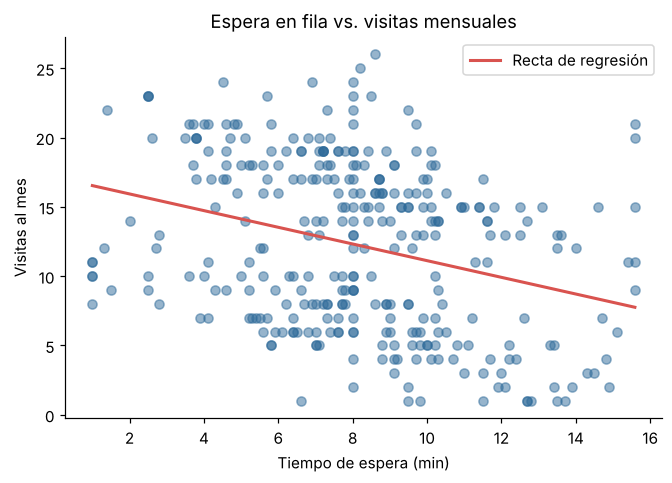

In [18]:
res = stats.linregress(df["tiempo_espera_min"], df["visitas_mes"])
r, p_r = stats.pearsonr(df["tiempo_espera_min"], df["visitas_mes"])
print(f"Pendiente = {res.slope:.3f} visitas/mes por cada minuto extra de espera")
print(f"Intercepto = {res.intercept:.2f}")
print(f"Pearson r = {r:.3f}  (p = {p_r:.2e})   |   R² = {r**2:.3f}")

x = np.linspace(df.tiempo_espera_min.min(), df.tiempo_espera_min.max(), 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(df.tiempo_espera_min, df.visitas_mes, alpha=.5, color="#2F6B9A")
plt.plot(x, res.intercept + res.slope * x, color="#D9534F", lw=2, label="Recta de regresión")
plt.xlabel("Tiempo de espera (min)"); plt.ylabel("Visitas al mes"); plt.legend()
plt.title("Espera en fila vs. visitas mensuales"); plt.show()

**Interpretación.** La pendiente es ≈ **−0.60**: en promedio, **cada minuto extra de espera se asocia con ≈ 0.6 visitas menos al mes**. El coeficiente de Pearson es **r ≈ −0.31** (relación negativa de intensidad **moderada-baja**) y el p-valor es prácticamente 0, así que la relación es estadísticamente significativa. Sin embargo **R² ≈ 0.09**: la espera explica solo ~9 % de la variación en las visitas; el resto depende de otros factores (el perfil del cliente, que se explora en la U5).

**Limitaciones.** (1) **Correlación no implica causalidad:** podría haber un tercer factor (p. ej. las horas pico tienen más fila y a la vez atraen a otro tipo de cliente). (2) La relación solo es válida dentro del rango observado (≈ 1–16 min tras el capping). (3) Los datos son un corte transversal, no seguimiento de la misma persona en el tiempo. Una prueba piloto (abrir una segunda caja en algunos turnos y comparar) daría evidencia causal.

---
## U5 · Técnica de exploración: K-means (segmentación de clientes)
Se segmenta con **visitas al mes, gasto por visita y antigüedad**, ya estandarizadas con z-score (U3).

### 5.1 Selección de k con el coeficiente de silueta

,k,silueta
0,2,0.412
1,3,0.442
2,4,0.513
3,5,0.511
4,6,0.436
5,7,0.396
6,8,0.325


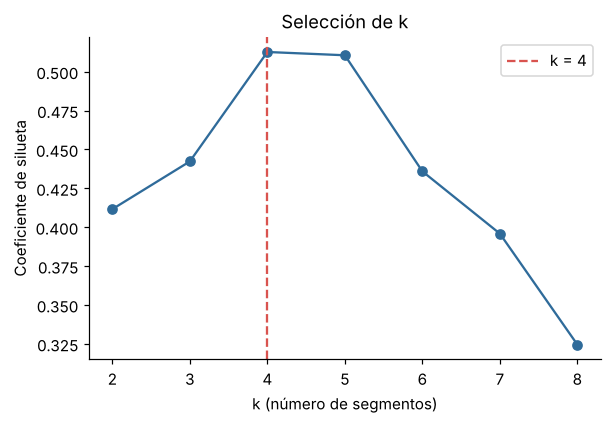

k elegido: 4


In [19]:
resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    resultados.append({"k": k, "silueta": silhouette_score(Z, km.labels_)})
sil = pd.DataFrame(resultados)
display(sil.round(3))

plt.figure(figsize=(6, 3.8))
plt.plot(sil.k, sil.silueta, marker="o", color="#2F6B9A")
mejor_k = int(sil.loc[sil.silueta.idxmax(), "k"])
plt.axvline(mejor_k, color="#D9534F", ls="--", label=f"k = {mejor_k}")
plt.xlabel("k (número de segmentos)"); plt.ylabel("Coeficiente de silueta"); plt.legend()
plt.title("Selección de k"); plt.show()
print("k elegido:", mejor_k)

**Por qué k = 4.** El coeficiente de silueta mide qué tan bien separados y cohesionados quedan los grupos (de −1 a 1; más alto es mejor). Alcanza su **máximo en k = 4 (≈ 0.513)**. Ojo: k = 5 queda prácticamente empatado (≈ 0.511), así que la silueta sola no decide; se elige **k = 4 por ser el máximo y por parsimonia** (menos grupos, cada uno con una acción distinta y fácil de explicar), y para k ≥ 6 la silueta baja claramente. Un valor de ~0.5 se considera una estructura razonable.

In [20]:
km = KMeans(n_clusters=mejor_k, n_init=10, random_state=42).fit(Z)
df["cluster"] = km.labels_
perfil = df.groupby("cluster")[vars_km].mean().round(1)
perfil["n_clientes"] = df.cluster.value_counts().sort_index()
perfil["% con tarjeta"] = (df.assign(t=df.tarjeta_lealtad == "Sí").groupby("cluster").t.mean() * 100).round(0)
perfil

,visitas_mes,gasto_promedio,antiguedad_meses,n_clientes,% con tarjeta
cluster,,,,,
0,7.1,52.6,2.3,91,23.0
1,15.3,88.8,23.0,77,83.0
2,18.3,42.3,13.8,95,52.0
3,6.2,106.9,11.0,57,28.0


In [21]:
# Nombrar los segmentos con reglas sobre el perfil (así el nombre no depende de la numeración aleatoria)
p = df.groupby("cluster")[vars_km].mean()
nuevos  = p["antiguedad_meses"].idxmin()
resto   = p.drop(nuevos)
gourmet = resto["visitas_mes"].idxmin()
resto   = resto.drop(gourmet)
premium = resto["gasto_promedio"].idxmax()
rutina  = resto["gasto_promedio"].idxmin()

nombres = {nuevos: "Nuevos curiosos", gourmet: "Gourmet ocasionales",
           premium: "Leales premium", rutina: "Habituales de rutina"}
df["segmento"] = df["cluster"].map(nombres)
orden = ["Habituales de rutina", "Leales premium", "Gourmet ocasionales", "Nuevos curiosos"]

resumen_seg = df.groupby("segmento")[vars_km + ["satisfaccion", "tiempo_espera_min"]].mean().round(1).loc[orden]
resumen_seg["n_clientes"] = df.segmento.value_counts()
resumen_seg

,visitas_mes,gasto_promedio,antiguedad_meses,satisfaccion,tiempo_espera_min,n_clientes
segmento,,,,,,
Habituales de rutina,18.3,42.3,13.8,8.4,8.3,95
Leales premium,15.3,88.8,23.0,8.3,7.9,77
Gourmet ocasionales,6.2,106.9,11.0,8.4,7.8,57
Nuevos curiosos,7.1,52.6,2.3,8.2,8.4,91


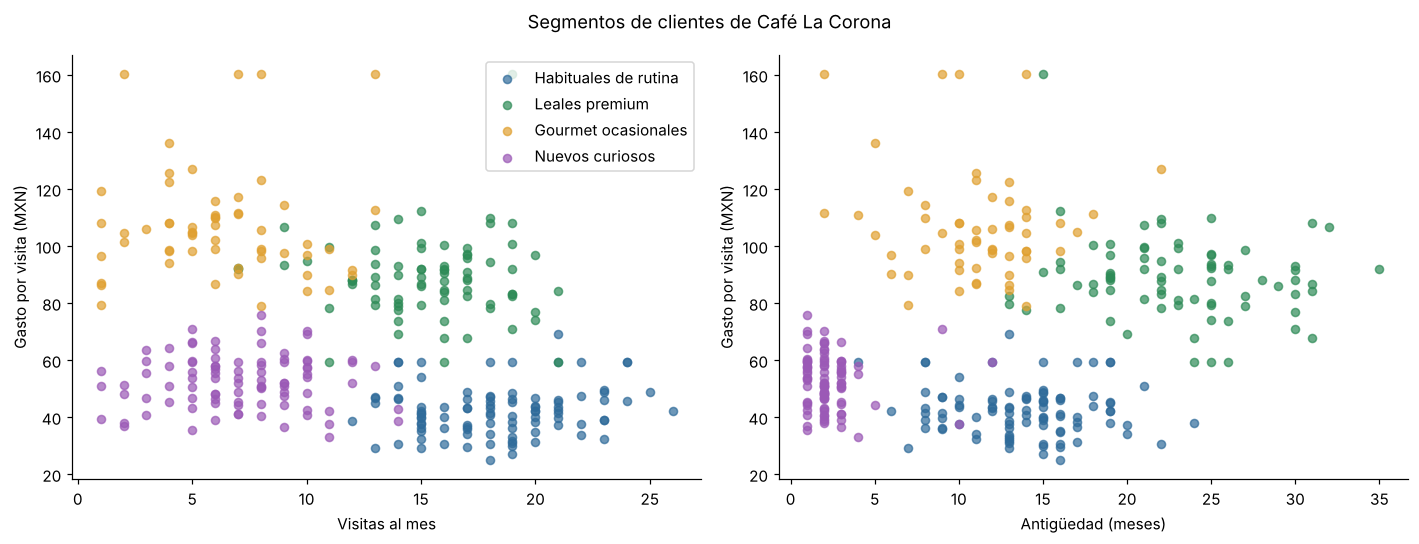

In [22]:
colores = {"Habituales de rutina": "#2F6B9A", "Leales premium": "#2E8B57",
           "Gourmet ocasionales": "#E0A030", "Nuevos curiosos": "#9B59B6"}
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for s in orden:
    d = df[df.segmento == s]
    axs[0].scatter(d.visitas_mes, d.gasto_promedio, s=28, alpha=.7, color=colores[s], label=s)
    axs[1].scatter(d.antiguedad_meses, d.gasto_promedio, s=28, alpha=.7, color=colores[s], label=s)
axs[0].set_xlabel("Visitas al mes"); axs[0].set_ylabel("Gasto por visita (MXN)")
axs[1].set_xlabel("Antigüedad (meses)"); axs[1].set_ylabel("Gasto por visita (MXN)")
axs[0].legend(); plt.suptitle("Segmentos de clientes de Café La Corona"); plt.tight_layout(); plt.show()

### 5.2 Los cuatro segmentos y una acción distinta para cada uno

| Segmento | Cómo es (con lenguaje de la cafetería) | Acción propuesta |
|---|---|---|
| **Habituales de rutina** (~30 %) | Vienen **casi todos los días** (≈ 18 visitas/mes), pero gastan poco (≈ 42 MXN: un café o un pan). Llevan más de un año. | **Combo prepago de desayuno** (café + pan a precio cerrado) para **subir el ticket** sin darles descuento general: ya vienen, hay que lograr que consuman un poco más. |
| **Leales premium** (~24 %) | Vienen seguido (≈ 15/mes), gastan mucho (≈ 89 MXN) y son los más antiguos (≈ 23 meses). La mayoría tiene tarjeta. | **No descontar.** Darles beneficios no monetarios: preventa de bebidas de temporada, acceso anticipado a nuevos productos, puntos dobles en eventos. Protegen el margen. |
| **Gourmet ocasionales** (~18 %) | Vienen poco (≈ 6/mes) pero cuando vienen gastan lo más alto (≈ 107 MXN). | **Subir su frecuencia:** cupón "tu próxima visita en la semana" y **pre-pedido por la app** (evita la fila, que según la U4 se asocia con menos visitas). |
| **Nuevos curiosos** (~28 %) | Se registraron hace ≈ 2 meses, vienen poco (≈ 7/mes) y gasto medio (≈ 53 MXN). | **Bienvenida y conversión a tarjeta:** 2×1 en la primera semana e invitación a la tarjeta de lealtad. Es el momento en que se forma el hábito. |

---
## Conclusión general y recomendación al administrador
1. **No dar el mismo descuento a todos.** Hay 4 tipos de cliente con comportamientos muy distintos; un descuento general se desperdicia en los *Leales premium* y los *Habituales*, que ya vienen.
2. **Prioridad de inversión:** convertir a los **Nuevos curiosos** en clientes con tarjeta (quienes tienen tarjeta gastan ≈ 8 MXN más por visita, aunque no se puede asegurar que sea por la tarjeta) y **reducir la espera**: cada minuto menos se asocia con ≈ 0.6 visitas más al mes.
3. **Siguiente paso recomendado:** una **prueba piloto** (abrir una segunda caja en el turno de mayor fila y ofrecer la tarjeta al azar) para confirmar con evidencia causal lo que aquí solo se observó como asociación.
4. **Calidad de datos:** registrar los pedidos de catering como categoría separada y alertar cuando la espera supere los 15 minutos (probable falla en caja).

**Limitaciones del estudio.** Datos simulados de un solo semestre; la segmentación depende de las tres variables elegidas; los segmentos son descriptivos, no predictivos.